# NB16: Data Preprocessing & Forcing Preparation

**Purpose**: Learn how to prepare input data for a RELIC simulation.

This is the RELIC equivalent of WRF's WPS preprocessing:
- **geogrid** -> Site metadata (location, PFT, soil type)
- **ungrib** -> Raw data extraction and formatting
- **metgrid** -> Gap filling and NetCDF creation with CF variable metadata

## What You Need

A RELIC site simulation draws on two types of input:
1. **Site metadata**: Location, plant functional type, soil properties (entering the
   Functors as parameters and state; see Part 5)
2. **Meteorological forcing**: Time series of temperature, precipitation, radiation, etc.

**Time**: ~5 minutes


In [1]:
# Standard-library event loop setup for nbconvert/Jupyter execution
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os
import sys
from pathlib import Path
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# ---------------------------------------------------------------
# References:
#   CF Conventions 1.8: http://cfconventions.org/
#   RELIC data standards: relic/data/standards/
# Mathematical expression:
#   No ecological computation in this cell; this cell prepares the RELIC data pipeline.
# Parameter meanings:
#   PROJECT_ROOT: RELIC repository root directory
#   OUTPUT_DIR: notebook artifact directory for temporary NetCDF outputs
# ---------------------------------------------------------------

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()

def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, DEFAULT_PROJECT_ROOT]
    for candidate in candidates:
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError("Could not locate RELIC project root from the active notebook environment.")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch
import xarray as xr

from relic.data.io.reader import DataReader, ReadConfig
from relic.data.io.writer import DataWriter, WriteConfig
from relic.data.standards.cf_conventions import CFConventions, CFAttributeSynchronizer
from relic.data.standards.unit_converter import UnitConverter
from relic.data.quality.validators import QualityValidator, RangeRule
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NB16_FORCING_PATH = OUTPUT_DIR / "16_tutorial_forcing_io.nc"

required_forcing = [
    ("air_temperature", "K", "Near-surface air temperature"),
    ("precipitation_flux", "kg m-2 s-1", "Precipitation rate"),
    ("surface_downwelling_shortwave_flux_in_air", "W m-2", "Incoming shortwave radiation"),
    ("relative_humidity", "1", "Near-surface relative humidity (0-1)"),
    ("wind_speed", "m s-1", "Near-surface wind speed"),
    ("atmospheric_pressure", "Pa", "Near-surface atmospheric pressure"),
    ("mole_fraction_of_carbon_dioxide_in_air", "ppm", "Atmospheric CO2 (stored as atmospheric_co2_ppm)"),
]

# Each Functor declares its own inputs; this list is the forcing prepared in this notebook.
print("=== Forcing Variables Prepared in This Notebook ===")
print(f"{'Prepared Field / CF Identifier':<55s} {'Units':<14s} {'Description'}")
print("-" * 100)
for name, units, desc in required_forcing:
    print(f"  {name:<53s} {units:<14s} {desc}")

print(f"\nTotal: {len(required_forcing)} forcing variables")
print("RELIC data preprocessing will use actual DataReader/DataWriter/CF/QC APIs.")
print(f"[OK] project_root = {PROJECT_ROOT}")
print(f"[OK] nb16_forcing_path = {NB16_FORCING_PATH}")

=== Forcing Variables Prepared in This Notebook ===
Prepared Field / CF Identifier                          Units          Description
----------------------------------------------------------------------------------------------------
  air_temperature                                       K              Near-surface air temperature
  precipitation_flux                                    kg m-2 s-1     Precipitation rate
  surface_downwelling_shortwave_flux_in_air             W m-2          Incoming shortwave radiation
  relative_humidity                                     1              Near-surface relative humidity (0-1)
  wind_speed                                            m s-1          Near-surface wind speed
  atmospheric_pressure                                  Pa             Near-surface atmospheric pressure
  mole_fraction_of_carbon_dioxide_in_air                ppm            Atmospheric CO2 (stored as atmospheric_co2_ppm)

Total: 7 forcing variables
RELIC data preproce

## Part 2: Building a Tutorial Forcing Tensor

This notebook generates a compact forcing tensor in place for API demonstration.
The values are not presented as site observations; they are prepared only to
exercise RELIC preprocessing, CF standardization, and downstream Functor calls.


In [2]:
# ---------------------------------------------------------------
# References:
#   CF Conventions 1.8 metadata rules
#   RELIC DataReader/DataWriter and CFConventions APIs
# Mathematical expression:
#   This cell builds a compact tutorial forcing tensor for preprocessing.
# Parameter meanings:
#   DT_SECONDS: tutorial forcing time step [s]
#   TIME_UNITS: CF-compliant numeric time units for RELIC IO [hours since reference]
#   n_steps: number of forcing records
# Units:
#   temperature [K], pressure [Pa], precipitation [kg m-2 s-1], radiation [W m-2].
# Domain/constraints:
#   Explicit synthetic forcing; canonical state keys are separate from CF standard names.
# Sign convention:
#   Precipitation is downward positive; no site observations are inferred from this dataset.
# ---------------------------------------------------------------

cf_conventions = CFConventions()
cf_synchronizer = CFAttributeSynchronizer(strict_mode=False)
unit_converter = UnitConverter()

DT_SECONDS = 1800.0
TIME_UNITS = "hours since 2000-07-01 00:00:00"
n_steps = 96
forcing_time_values = torch.arange(n_steps, dtype=torch.float32) * (DT_SECONDS / 3600.0)
forcing_time_coord = forcing_time_values.detach().cpu().tolist()
step_index = torch.arange(n_steps, dtype=torch.float32)
hour_of_day = torch.remainder(forcing_time_values, 24.0)

air_temperature_c = 24.0 + 5.5 * torch.sin(2.0 * torch.pi * (hour_of_day - 6.0) / 24.0)
air_temperature = unit_converter.convert(air_temperature_c, "air_temperature", "C", "K").to(torch.float32)
shortwave = 780.0 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 6.0) / 12.0), min=0.0)
relative_humidity = torch.clamp(0.72 - 0.18 * torch.sin(2.0 * torch.pi * (hour_of_day - 8.0) / 24.0), min=0.35, max=0.95)
wind_speed = torch.clamp(1.4 + 0.7 * torch.sin(2.0 * torch.pi * hour_of_day / 24.0), min=0.2)
air_pressure_hpa = 1008.0 + 3.5 * torch.sin(2.0 * torch.pi * step_index / n_steps)
atmospheric_pressure = unit_converter.convert(air_pressure_hpa, "atmospheric_pressure", "hPa", "Pa").to(torch.float32)
atmospheric_co2_ppm = torch.full((n_steps,), 410.0, dtype=torch.float32)
precipitation_flux = torch.zeros(n_steps, dtype=torch.float32)
precipitation_flux[18:22] = 3.0e-4
precipitation_flux[60:63] = 8.0e-4

forcing_tensor_map = {
    "air_temperature": air_temperature,
    "surface_downwelling_shortwave_flux_in_air": shortwave,
    "relative_humidity": relative_humidity,
    "wind_speed": wind_speed,
    "atmospheric_pressure": atmospheric_pressure,
    "atmospheric_co2_ppm": atmospheric_co2_ppm,
    "precipitation_flux": precipitation_flux,
}

forcing_cf_contracts = {
    "air_temperature": ("air_temperature", "K"),
    "surface_downwelling_shortwave_flux_in_air": ("surface_downwelling_shortwave_flux_in_air", "W m-2"),
    "relative_humidity": ("relative_humidity", "1"),
    "wind_speed": ("wind_speed", "m s-1"),
    "atmospheric_pressure": ("air_pressure", "Pa"),
    "atmospheric_co2_ppm": ("mole_fraction_of_carbon_dioxide_in_air", "ppm"),
    "precipitation_flux": ("precipitation_flux", "kg m-2 s-1"),
}
forcing_data_vars = {}
for variable_name, tensor in forcing_tensor_map.items():
    standard_name, units = forcing_cf_contracts[variable_name]
    metadata = {
        "standard_name": standard_name,
        "units": units,
        "coordinates": "time",
        "long_name": variable_name.replace("_", " "),
    }
    synced_attrs = cf_conventions.sync_variable_attributes(tensor, metadata)
    forcing_data_vars[variable_name] = xr.DataArray(
        tensor.detach().cpu().tolist(),
        dims=["time"],
        coords={"time": forcing_time_coord},
        attrs=synced_attrs,
    )

tutorial_forcing_ds = xr.Dataset(
    data_vars=forcing_data_vars,
    coords={"time": forcing_time_coord},
    attrs=cf_conventions.create_global_attributes(
        title="NB16 tutorial forcing dataset",
        institution="RELIC tutorial",
        source="In-notebook forcing tensor for RELIC preprocessing tutorial",
        history="Created in NB16 using torch tensors and RELIC CF APIs",
    ),
)
tutorial_forcing_ds["time"].attrs = {
    "standard_name": "time",
    "long_name": "time",
    "units": TIME_UNITS,
    "calendar": "gregorian",
    "axis": "T",
}

print("=== Tutorial Forcing Tensor ===")
print(f"  Time step: {DT_SECONDS:.0f} s")
print(f"  Records:   {n_steps}")
print(f"  T range:   {float(air_temperature.min()):.2f} - {float(air_temperature.max()):.2f} K")
print(f"  SW range:  {float(shortwave.min()):.2f} - {float(shortwave.max()):.2f} W m-2")
print(f"  RH range:  {float(relative_humidity.min()):.2f} - {float(relative_humidity.max()):.2f}")
print(f"  Wind:      {float(wind_speed.min()):.2f} - {float(wind_speed.max()):.2f} m s-1")
print(f"  Pressure:  {float(atmospheric_pressure.min()):.2f} - {float(atmospheric_pressure.max()):.2f} Pa")
print(f"  Precip sum: {float((precipitation_flux * DT_SECONDS).sum()):.4f} kg m-2")
print("  Variables:")
for variable_name in tutorial_forcing_ds.data_vars:
    print(f"    {variable_name}: units={tutorial_forcing_ds[variable_name].attrs.get('units', '')}")

=== Tutorial Forcing Tensor ===
  Time step: 1800 s
  Records:   96
  T range:   291.65 - 302.65 K
  SW range:  0.00 - 780.00 W m-2
  RH range:  0.54 - 0.90
  Wind:      0.70 - 2.10 m s-1
  Pressure:  100450.00 - 101150.00 Pa
  Precip sum: 6.4800 kg m-2
  Variables:
    air_temperature: units=K
    surface_downwelling_shortwave_flux_in_air: units=W m-2
    relative_humidity: units=1
    wind_speed: units=m s-1
    atmospheric_pressure: units=Pa
    atmospheric_co2_ppm: units=ppm
    precipitation_flux: units=kg m-2 s-1


## Part 3: Quality Control & Gap Filling

Real-world data often contains gaps, outliers, and unrealistic values.
RELIC's QC pipeline catches these issues before they corrupt a simulation.

The temporal QC settings (coverage threshold, longest fillable gap, gap-filling
and outlier methods, outlier threshold, minimum valid samples for outlier
detection, IQR fence factor, grade cutoffs) come from the parameter database
through `QualityConfig.from_parameter_manager()`; `QualityConfig` has no Python
defaults. Coverage is the (optionally time-weighted) fraction of finite samples
in each series. A series below the coverage threshold is counted in
`insufficient_coverage_count` and makes `validate_for_operation` fail; it does
not flag individual samples. `validate_for_operation` also requires the quality
level graded from the unflagged sample fraction to be at least `ACCEPTABLE` for
`'aggregation'` or `GOOD` for `'disaggregation'`.

In [3]:
# ---------------------------------------------------------------
# References:
#   RELIC data.quality.validators
#   RELIC coupling.scales.temporal.quality_control
# Mathematical expression:
#   Range check: x in [x_min, x_max] (QualityValidator reports violations; this cell then sets
#   out-of-range samples to NaN itself)
#   Gap fill: linear interpolation along the time coordinate for runs of at most
#   max_gap_length missing samples (gap_filling_method from the parameter database)
#   Outliers: z-score detection flags samples (bit 3) and never changes their values
# Parameter meanings:
#   qc_temperature_dirty: forcing series with controlled faults for QC demonstration
#   qc_temperature_filled: gap-filled output from RELIC GapFiller
#   quality_config: QC thresholds loaded from the parameter database
# ---------------------------------------------------------------

from relic.coupling.scales.temporal.core import TimeCoordinate
from relic.coupling.scales.temporal.quality_control import (
    GapFiller,
    QualityConfig,
    QualityController,
)

qc_temperature_dirty = forcing_tensor_map["air_temperature"].clone()
qc_temperature_dirty[10] = 180.0
qc_temperature_dirty[44] = 360.0
qc_temperature_dirty[60:64] = float("nan")
qc_temperature_dirty[81:83] = float("nan")

qc_shortwave_dirty = forcing_tensor_map["surface_downwelling_shortwave_flux_in_air"].clone()
qc_shortwave_dirty[28] = -25.0
qc_shortwave_dirty[72] = 1500.0

qc_dataset = tutorial_forcing_ds.copy(deep=True)
qc_dataset["air_temperature"] = xr.DataArray(
    qc_temperature_dirty.detach().cpu().tolist(),
    dims=["time"],
    coords={"time": forcing_time_coord},
    attrs=tutorial_forcing_ds["air_temperature"].attrs,
)
qc_dataset["surface_downwelling_shortwave_flux_in_air"] = xr.DataArray(
    qc_shortwave_dirty.detach().cpu().tolist(),
    dims=["time"],
    coords={"time": forcing_time_coord},
    attrs=tutorial_forcing_ds["surface_downwelling_shortwave_flux_in_air"].attrs,
)
qc_dataset["time"].attrs = dict(tutorial_forcing_ds["time"].attrs)

validator = QualityValidator(
    range_rules={
        "air_temperature": RangeRule(min_value=230.0, max_value=330.0),
        "surface_downwelling_shortwave_flux_in_air": RangeRule(min_value=0.0, max_value=1400.0),
        "relative_humidity": RangeRule(min_value=0.0, max_value=1.0),
    },
    expected_units={
        "air_temperature": "K",
        "surface_downwelling_shortwave_flux_in_air": "W m-2",
        "relative_humidity": "1",
    },
    max_time_gap_seconds=3.0 * DT_SECONDS,
)
qc_is_valid, qc_report = validator.check_data(qc_dataset)

# Every QC threshold is read from the parameter database
# (coupling.scales.temporal.coverage_threshold and
# coupling.scales.temporal.quality_control.*); QualityConfig has no defaults.
quality_config = QualityConfig.from_parameter_manager()
quality_controller = QualityController(quality_config)
gap_filler = GapFiller(quality_config)

time_coord = TimeCoordinate(
    values=forcing_time_values,
    units=TIME_UNITS,
    calendar="gregorian",
)

range_invalid_mask = (
    torch.isnan(qc_temperature_dirty)
    | (qc_temperature_dirty < 230.0)
    | (qc_temperature_dirty > 330.0)
)
qc_temperature_input = qc_temperature_dirty.clone()
qc_temperature_input[range_invalid_mask] = float("nan")
# assess_quality returns (processed_data, quality_flags, metrics): the gap-filled series,
# the per-sample flags, and the series metrics.
qc_temperature_assessed, qc_flags, qc_metrics = quality_controller.assess_quality(qc_temperature_input, time_coord)
qc_temperature_filled, interpolated_mask = gap_filler.fill_gaps(
    qc_temperature_input,
    time_coord,
    torch.isnan(qc_temperature_input),
)
qc_flags.set_flag(torch.where(interpolated_mask)[0], 2)

qc_dataset_clean = qc_dataset.copy(deep=True)
qc_dataset_clean["air_temperature"] = xr.DataArray(
    qc_temperature_filled.detach().cpu().tolist(),
    dims=["time"],
    coords={"time": forcing_time_coord},
    attrs=tutorial_forcing_ds["air_temperature"].attrs,
)
qc_dataset_clean["surface_downwelling_shortwave_flux_in_air"] = xr.DataArray(
    forcing_tensor_map["surface_downwelling_shortwave_flux_in_air"].detach().cpu().tolist(),
    dims=["time"],
    coords={"time": forcing_time_coord},
    attrs=tutorial_forcing_ds["surface_downwelling_shortwave_flux_in_air"].attrs,
)
qc_dataset_clean["time"].attrs = dict(tutorial_forcing_ds["time"].attrs)

print("=== Quality Control Pipeline ===")
print(f"  Validation passed: {qc_is_valid}")
print(f"  Reported issues:   {qc_report['total_issues']}")
for issue in qc_report["issues"]:
    details = issue.get("details") or {}
    print(f"    {issue['variable']} | {issue['check']} | {issue['message']} | details={details}")
print(
    "  QC parameters:    ",
    f"coverage_threshold={quality_config.coverage_threshold},",
    f"max_gap_length={quality_config.max_gap_length},",
    f"outlier_threshold={quality_config.outlier_threshold}",
)
print(f"  Coverage fraction: {qc_metrics.coverage_fraction:.3f}")
print(f"  Gap count:         {qc_metrics.gap_count}")
print(f"  Max gap length:    {qc_metrics.max_gap_length}")
print(f"  Interpolated:      {int(interpolated_mask.sum().item())}")
print(f"  Quality level:     {qc_metrics.quality_level.value}")
print(f"  Below coverage threshold: {qc_metrics.insufficient_coverage_count} series")
print(f"  Operation valid:   {quality_controller.validate_for_operation(qc_temperature_filled, time_coord, 'aggregation')}")

=== Quality Control Pipeline ===
  Validation passed: False
  Reported issues:   4
    air_temperature | range | Values below minimum bound 230.0. | details={'violations': 1}
    air_temperature | range | Values above maximum bound 330.0. | details={'violations': 1}
    surface_downwelling_shortwave_flux_in_air | range | Values below minimum bound 0.0. | details={'violations': 1}
    surface_downwelling_shortwave_flux_in_air | range | Values above maximum bound 1400.0. | details={'violations': 1}
  QC parameters:     coverage_threshold=0.8, max_gap_length=7, outlier_threshold=3.0
  Coverage fraction: 0.917
  Gap count:         4
  Max gap length:    4
  Interpolated:      8
  Quality level:     good
  Below coverage threshold: 0 series
  Operation valid:   True


## Part 4: CF-1.8 Compliance & Unit Conversion

RELIC uses CF (Climate and Forecast) conventions for variable naming and units.
These variable-level checks support data exchange; they do not certify a full
dataset or prove live coupling to another Earth system model. The RELIC field
`atmospheric_pressure` uses the official CF standard name `air_pressure`.


In [4]:
# ---------------------------------------------------------------
# References:
#   CF Conventions 1.8
#   RELIC cf_conventions and unit_converter modules
# Mathematical expression:
#   CF naming: alias -> standard_name
#   Unit conversion: x_target = Convert(x_source)
# Parameter meanings:
#   standard_name: CF-1.8 canonical variable identifier
#   target_units: canonical units used by RELIC IO and validation
# ---------------------------------------------------------------

from relic.data import check_cf_variable_metadata, get_standard_units, standardize_variable_name

exact_standard_names = [
    "air_temperature",
    "precipitation_flux",
    "surface_downwelling_shortwave_flux_in_air",
    "mole_fraction_of_carbon_dioxide_in_air",
]
rejected_implicit_aliases = ["temp", "temperature", "Tair", "precip", "rainfall", "shortwave", "SW_down"]

print("=== CF-1.8 Variable Name Standardization ===")
print(f"  {'User Input':<25s} -> {'CF Standard Name':<50s} {'Units'}")
print("  " + "-" * 105)
for name in exact_standard_names:
    standard_name = standardize_variable_name(name)
    units = get_standard_units(standard_name)
    print(f"  {name:<25s} -> {standard_name:<50s} {units}")
for alias in rejected_implicit_aliases:
    try:
        standardize_variable_name(alias)
    except ValueError:
        continue
    raise AssertionError(f"Implicit CF alias should fail closed: {alias}")

print("\n=== RELIC Unit Conversion Examples ===")
air_temperature_kelvin = unit_converter.convert(torch.tensor([25.0]), "air_temperature", "C", "K")
surface_pressure_pa = unit_converter.convert(torch.tensor([1013.25]), "surface_pressure", "hPa", "Pa")
vpd_kpa = unit_converter.convert(torch.tensor([1200.0]), "vapor_pressure_deficit", "Pa", "kPa")
print(f"  25.0 C      -> {float(air_temperature_kelvin.item()):.2f} K")
print(f"  1013.25 hPa -> {float(surface_pressure_pa.item()):.2f} Pa")
print(f"  1200.0 Pa   -> {float(vpd_kpa.item()):.2f} kPa")

sample_metadata = {
    "standard_name": "air_temperature",
    "units": "K",
    "long_name": "air temperature",
    "coordinates": "time",
}
sample_metadata = cf_conventions.sync_variable_attributes(
    forcing_tensor_map["air_temperature"],
    sample_metadata,
)
cf_validation = check_cf_variable_metadata(sample_metadata)
is_cf_compliant = cf_validation.is_valid
cf_issues = list(cf_validation.issues)
print(f"\n  Sample metadata compliant: {is_cf_compliant}")
print(f"  Sample metadata issues:    {cf_issues}")


=== CF-1.8 Variable Name Standardization ===
  User Input                -> CF Standard Name                                   Units
  ---------------------------------------------------------------------------------------------------------
  air_temperature           -> air_temperature                                    K
  precipitation_flux        -> precipitation_flux                                 kg m-2 s-1
  surface_downwelling_shortwave_flux_in_air -> surface_downwelling_shortwave_flux_in_air          W m-2
  mole_fraction_of_carbon_dioxide_in_air -> mole_fraction_of_carbon_dioxide_in_air             1

=== RELIC Unit Conversion Examples ===
  25.0 C      -> 298.15 K
  1013.25 hPa -> 101325.00 Pa
  1200.0 Pa   -> 1.20 kPa

  Sample metadata compliant: True
  Sample metadata issues:    []


## Part 5: Site Metadata Configuration

A site description records what a site simulation is built from:
- Geographic coordinates (for radiation calculations)
- Soil properties (for hydrological processes)
- Plant functional type (for biological processes)

RELIC has no site-configuration reader: the record below is a plain dictionary that
documents the site. Functors receive these quantities as parameters (the parameter
database and the PFT registry in `relic.scientific.biosphere.pft`) and as state or
forcing variables. The PFT entry uses the `PFTCategory` value
`broadleaf_evergreen_tropical`.


In [5]:
# ---------------------------------------------------------------
# References:
#   AmeriFlux site metadata: https://ameriflux.lbl.gov/
#   Illustrative site record (RELIC has no site-configuration reader)
# Mathematical expression:
#   No computation -- declares site metadata structure
# Parameter meanings:
#   lat, lon: geographic coordinates [degrees]
#   elevation: meters above sea level
#   pft: plant functional type category (PFTCategory value in relic.scientific.biosphere.pft)
#   soil_texture: USDA soil classification
# ---------------------------------------------------------------

import json

# Example: Tapajos KM67 tower site (Amazon rainforest)
site_config = {
    "site_id": "BR-Sa1",
    "site_name": "Tapajos KM67 (Santarem)",
    "location": {
        "latitude": -2.857,
        "longitude": -54.959,
        "elevation_m": 130.0,
        "timezone": "UTC-3",
    },
    "vegetation": {
        "pft": "broadleaf_evergreen_tropical",
        "canopy_height_m": 35.0,
        "lai_max": 6.0,
        "leaf_age_max_days": 365,
    },
    "soil": {
        "texture": "clay_loam",
        "depth_m": 10.0,
        "n_layers": 10,
        "organic_carbon_percent": 2.5,
    },
    "forcing": {
        "source": "LBA-ECO tower measurements + ERA5 gap-fill",
        "temporal_resolution": "hourly",
        "period": "2002-2006",
    },
}

print("=== Site Configuration: Tapajos KM67 ===")
print(json.dumps(site_config, indent=2))
print()
print("This dictionary documents the site; no RELIC API reads it in this notebook.")
print("  PFT parameters: parameter database / PFT registry (relic.scientific.biosphere.pft)")
print("  Forcing: the NetCDF file written in Part 6, read back with DataReader")


=== Site Configuration: Tapajos KM67 ===
{
  "site_id": "BR-Sa1",
  "site_name": "Tapajos KM67 (Santarem)",
  "location": {
    "latitude": -2.857,
    "longitude": -54.959,
    "elevation_m": 130.0,
    "timezone": "UTC-3"
  },
  "vegetation": {
    "pft": "broadleaf_evergreen_tropical",
    "canopy_height_m": 35.0,
    "lai_max": 6.0,
    "leaf_age_max_days": 365
  },
  "soil": {
    "texture": "clay_loam",
    "depth_m": 10.0,
    "n_layers": 10,
    "organic_carbon_percent": 2.5
  },
  "forcing": {
    "source": "LBA-ECO tower measurements + ERA5 gap-fill",
    "temporal_resolution": "hourly",
    "period": "2002-2006"
  }
}

This dictionary documents the site; no RELIC API reads it in this notebook.
  PFT parameters: parameter database / PFT registry (relic.scientific.biosphere.pft)
  Forcing: the NetCDF file written in Part 6, read back with DataReader


## Part 6: Building a NetCDF Forcing File

The final preprocessing step: assemble all prepared data into a NetCDF file with
CF variable metadata (`standard_name`, `units`) that RELIC can read back.
`DataWriter` checks each variable's standard name and units; it does not evaluate
dataset-level CF conformance, so `WriteResult.cf_compliant` stays `False`.

The cell then drives `FarquharPhotosynthesis` and `PenmanMonteithET` with the tensors read
back from the file. Warnings that these calls raise (`warnings`) or log (FunctorBase
input/output validation, logger `relic.core.functor.functor_base`) are counted by kind and
printed with one example message.


In [6]:
# ---------------------------------------------------------------
# References:
#   NetCDF CF-1.8 conventions
#   RELIC data.io module
#   Allen et al. (1998), FAO-56 (Penman-Monteith, hourly soil heat flux Eqs. 45-46)
# Mathematical expression:
#   No new scientific law in this cell; this cell writes, reads, and reuses forcing through RELIC IO.
#   Driver check inputs (tutorial approximations): PPFD = 1.8 * SW, clipped to [0, 2500];
#   Rn = 0.78 * SW, clipped at 0; r_s = 120 s m-1.
#   PenmanMonteithET (canopy_resistance_source="state") reads net_radiation, air_temperature,
#   wind_speed, atmospheric_pressure (required) and relative_humidity, surface_resistance
#   (optional ports); without aerodynamic_resistance it computes g_a from wind_speed
#   (FAO-56 profile); the soil heat flux is G = 0.1 Rn for Rn > 0 and 0.5 Rn otherwise.
# Parameter meanings:
#   write_result: DataWriter result summary
#   read_result: DataReader result summary
#   SW: surface_downwelling_shortwave_flux_in_air; Rn: net_radiation; r_s: surface resistance
# Units: SW, Rn [W m-2]; PPFD [umol m-2 s-1]; r_s [s m-1]; GPP [kg C m-2 s-1]; ET [kg m-2 s-1]
# Domain/constraints: the FAO-56 hourly G ratios hold for dt <= 3600 s
#   (hydrosphere.physical.soil_heat_flux_hourly_max_step); DT_SECONDS = 1800 s.
# Sign convention: positive ET removes water from the surface; G > 0 is heat into the soil.
# ---------------------------------------------------------------

import logging
import warnings
from relic.core.state import UpdateItem

reader = DataReader(
    ReadConfig(
        cf_validate=True,
        cf_standardize=True,
        process_time=False,
        time_bounds=False,
        strict_cf=False,
        validate_data=False,
    )
)
writer = DataWriter(
    WriteConfig(
        title="NB16 tutorial forcing dataset",
        institution="RELIC tutorial",
        source="NB16 in-notebook forcing tensor",
        references="RELIC data.io + CF-1.8",
        comment="Written by RELIC DataWriter from an in-notebook tensor dataset",
        add_bounds=False,
    )
)

write_result = writer.write_dataset(qc_dataset_clean, NB16_FORCING_PATH)
read_result = reader.read_dataset(NB16_FORCING_PATH)
nb16_forcing_ds = read_result.data
nb16_tensors = reader.read_tensors(
    NB16_FORCING_PATH,
    variables=[
        "air_temperature",
        "surface_downwelling_shortwave_flux_in_air",
        "relative_humidity",
        "wind_speed",
        "atmospheric_pressure",
        "atmospheric_co2_ppm",
        "precipitation_flux",
    ],
    validate_data=False,
)

def unwrap_update_tensor(value: object) -> torch.Tensor:
    if isinstance(value, UpdateItem):
        return torch.as_tensor(value.value, dtype=torch.float32).reshape(-1)
    return torch.as_tensor(value, dtype=torch.float32).reshape(-1)

par_driver = torch.clamp(nb16_tensors["surface_downwelling_shortwave_flux_in_air"] * 1.8, min=0.0, max=2500.0)
photo_demo = FarquharPhotosynthesis(name="nb16_farquhar_driver_check", enable_gpu=False)
photo_state = {
    "air_temperature": nb16_tensors["air_temperature"],
    "atmospheric_co2_ppm": nb16_tensors["atmospheric_co2_ppm"],
    "ppfd": par_driver,
    "vcmax_scaling": torch.ones_like(par_driver),
    "jmax_scaling": torch.ones_like(par_driver),
    "water_stress_factor": torch.ones_like(par_driver),
    "temperature_stress_factor": torch.ones_like(par_driver),
    "ozone_stress_factor": torch.ones_like(par_driver),
    "leaf_area_index": torch.full_like(par_driver, 3.0),
    "vapor_pressure_deficit": torch.full_like(par_driver, 1000.0),
    "leaf_water_potential": torch.full_like(par_driver, -0.3),
}
et_demo = PenmanMonteithET(
    name="nb16_penman_driver_check",
    config={"canopy_resistance_source": "state"},
)

class FunctorLogCollector(logging.Handler):
    """Collect the warnings that FunctorBase logs for the governed calls of this cell."""

    def __init__(self) -> None:
        super().__init__(level=logging.WARNING)
        self.messages: list[str] = []

    def emit(self, record: logging.LogRecord) -> None:
        self.messages.append(record.getMessage())


# FunctorBase logs its L1 input/output validation findings once per call; they are
# collected here and summarized by kind below (count plus one example message).
functor_logger = logging.getLogger("relic.core.functor.functor_base")
functor_log_collector = FunctorLogCollector()
functor_logger_propagate = functor_logger.propagate
functor_logger.addHandler(functor_log_collector)
functor_logger.propagate = False
try:
    with warnings.catch_warnings(record=True) as caught_driver_warnings:
        warnings.simplefilter("always", UserWarning)
        photo_output = photo_demo(photo_state, time=0.0, dt=DT_SECONDS)

        et_step_values = []
        for idx in range(n_steps):
            air_temp_step = nb16_tensors["air_temperature"][idx:idx + 1]
            relative_humidity_step = nb16_tensors["relative_humidity"][idx:idx + 1]
            wind_speed_step = nb16_tensors["wind_speed"][idx:idx + 1]
            surface_resistance_step = torch.full_like(air_temp_step, 120.0)
            et_state = {
                "net_radiation": torch.clamp(nb16_tensors["surface_downwelling_shortwave_flux_in_air"][idx:idx + 1] * 0.78, min=0.0),
                "air_temperature": air_temp_step,
                "wind_speed": wind_speed_step,
                "atmospheric_pressure": nb16_tensors["atmospheric_pressure"][idx:idx + 1],
                "relative_humidity": relative_humidity_step,
                "surface_resistance": surface_resistance_step,
            }
            et_step_output = et_demo(et_state, time=float(idx * DT_SECONDS), dt=DT_SECONDS)
            et_step_values.append(unwrap_update_tensor(et_step_output["evapotranspiration_flux"])[0])
finally:
    functor_logger.removeHandler(functor_log_collector)
    functor_logger.propagate = functor_logger_propagate

driver_warning_records = [str(item.message) for item in caught_driver_warnings] + functor_log_collector.messages
driver_warning_summary: dict[str, int] = {}
driver_warning_examples: dict[str, str] = {}
for message in driver_warning_records:
    if "Conservation law 'carbon'" in message:
        label = 'Farquhar carbon conservation'
    elif "Conservation law 'energy'" in message:
        label = 'Farquhar energy conservation'
    elif "Conservation law 'water'" in message:
        label = 'Penman water conservation'
    elif 'Input variable' in message:
        label = 'Functor input-variable validation'
    elif 'Output variable' in message:
        label = 'Functor output-variable validation'
    else:
        label = 'Other tutorial warning'
    driver_warning_summary[label] = driver_warning_summary.get(label, 0) + 1
    driver_warning_examples.setdefault(label, message)

gpp_driver_series = unwrap_update_tensor(photo_output["gross_primary_productivity"]).detach().cpu()
et_driver_series = torch.stack(et_step_values).reshape(-1).detach().cpu()

print("=== Forcing Dataset Structure ===")
print(f"  Output path:        {write_result.output_path}")
print(f"  Variables written:  {len(write_result.variables_written)}")
print(f"  Coordinates added:  {write_result.coordinates_added}")
print(f"  File size:          {write_result.file_size} bytes")
print(f"  CF compliant:       {write_result.cf_compliant}")
# ReadResult.variables_read names every data variable returned by this read.
assert set(read_result.variables_read) == set(nb16_forcing_ds.data_vars)
print(f"  Variables returned: {read_result.variables_read}")
print(f"  Dataset variables:  {list(nb16_forcing_ds.data_vars)}")
print(f"  Time processed:     {read_result.time_processed}")
print(f"  Validation passed:  {read_result.validation_passed}")
print(f"  Driver warning kinds: {len(driver_warning_summary)}")
for label, count in sorted(driver_warning_summary.items()):
    print(f"  Driver warning:     {label} x{count}")
    print(f"    example: {driver_warning_examples[label]}")
print(f"  GPP range:          {float(gpp_driver_series.min()):.3e} - {float(gpp_driver_series.max()):.3e} kg C m-2 s-1")
print(f"  ET range:           {float(et_driver_series.min()):.3e} - {float(et_driver_series.max()):.3e} kg m-2 s-1")

=== Forcing Dataset Structure ===
  Output path:        tutorial\primary\output\16_tutorial_forcing_io.nc
  Variables written:  7
  Coordinates added:  []
  File size:          44701 bytes
  CF compliant:       False
  Variables returned: ['air_temperature', 'surface_downwelling_shortwave_flux_in_air', 'relative_humidity', 'wind_speed', 'atmospheric_pressure', 'atmospheric_co2_ppm', 'precipitation_flux']
  Dataset variables:  ['air_temperature', 'surface_downwelling_shortwave_flux_in_air', 'relative_humidity', 'wind_speed', 'atmospheric_pressure', 'atmospheric_co2_ppm', 'precipitation_flux']
  Time processed:     False
  Validation passed:  True
  Driver warning kinds: 0
  GPP range:          0.000e+00 - 2.507e-07 kg C m-2 s-1
  ET range:           7.368e-06 - 1.485e-04 kg m-2 s-1


---
## Visualization: Data Quality Control

Visualize data preprocessing steps, gap detection, and QC flags.


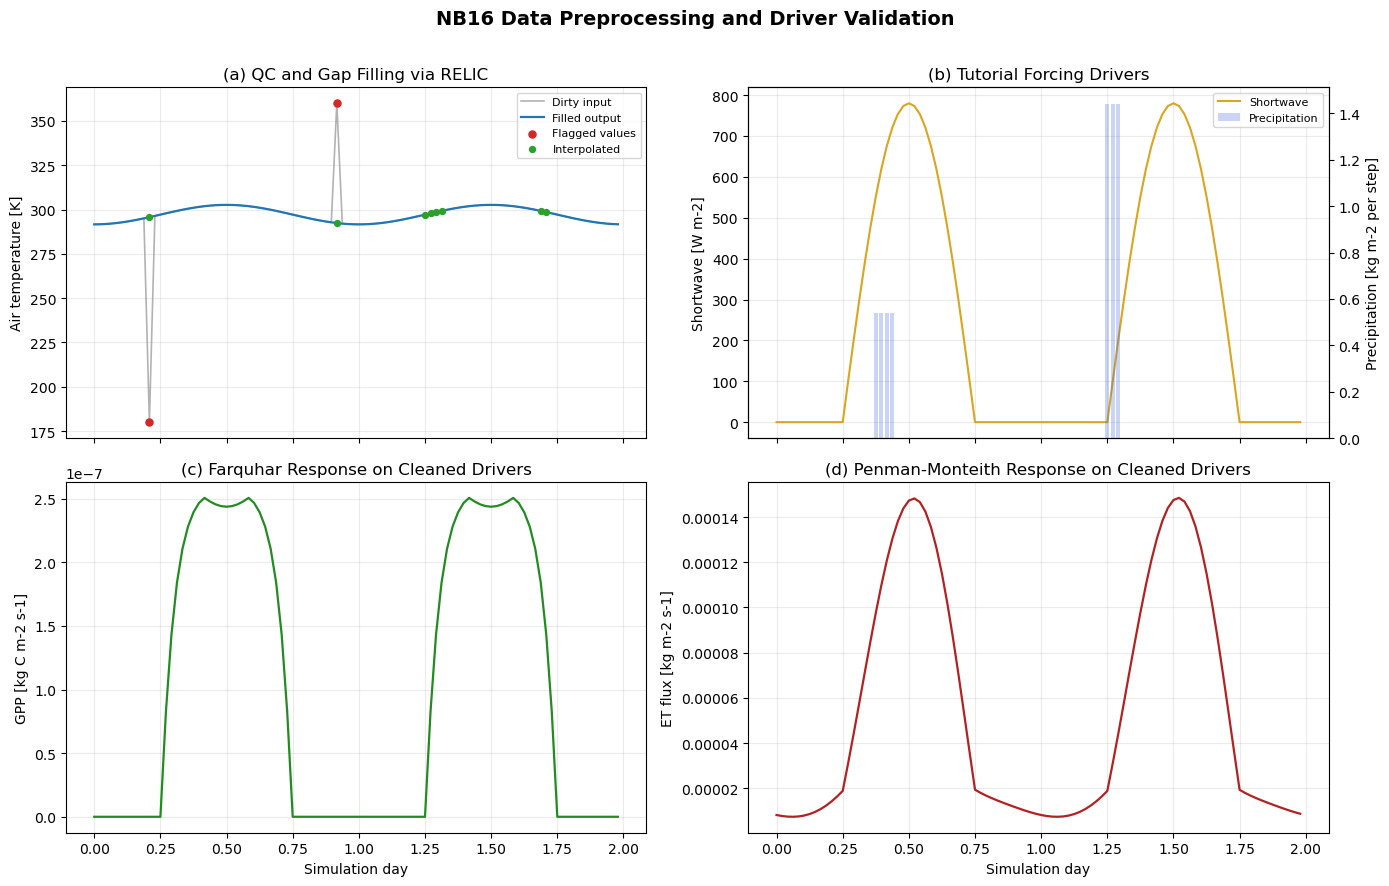

In [7]:
# === Data Preprocessing Visualization ===
import matplotlib.pyplot as plt

plot_days = (torch.arange(n_steps, dtype=torch.float32) * DT_SECONDS / 86400.0).detach().cpu()
gap_indices = torch.where(range_invalid_mask)[0].detach().cpu()
interp_indices = torch.where(interpolated_mask)[0].detach().cpu()

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

ax = axes[0, 0]
ax.plot(plot_days.tolist(), qc_temperature_dirty.detach().cpu().tolist(), color="gray", lw=1.2, alpha=0.6, label="Dirty input")
ax.plot(plot_days.tolist(), qc_temperature_filled.detach().cpu().tolist(), color="tab:blue", lw=1.6, label="Filled output")
if gap_indices.numel() > 0:
    ax.scatter((gap_indices.to(torch.float32) * DT_SECONDS / 86400.0).tolist(), qc_temperature_dirty[gap_indices].detach().cpu().tolist(),
               color="tab:red", s=26, label="Flagged values", zorder=5)
if interp_indices.numel() > 0:
    ax.scatter((interp_indices.to(torch.float32) * DT_SECONDS / 86400.0).tolist(), qc_temperature_filled[interp_indices].detach().cpu().tolist(),
               color="tab:green", s=18, label="Interpolated", zorder=6)
ax.set_ylabel("Air temperature [K]")
ax.set_title("(a) QC and Gap Filling via RELIC")
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8, loc="best")

ax = axes[0, 1]
ax.plot(plot_days.tolist(), forcing_tensor_map["surface_downwelling_shortwave_flux_in_air"].detach().cpu().tolist(),
        color="goldenrod", lw=1.5, label="Shortwave")
ax2 = ax.twinx()
ax2.bar(plot_days.tolist(), (forcing_tensor_map["precipitation_flux"] * DT_SECONDS).detach().cpu().tolist(),
        width=0.015, color="royalblue", alpha=0.28, label="Precipitation")
ax.set_ylabel("Shortwave [W m-2]")
ax2.set_ylabel("Precipitation [kg m-2 per step]")
ax.set_title("(b) Tutorial Forcing Drivers")
ax.grid(True, alpha=0.25)
handles_a, labels_a = ax.get_legend_handles_labels()
handles_b, labels_b = ax2.get_legend_handles_labels()
ax.legend(handles_a + handles_b, labels_a + labels_b, fontsize=8, loc="upper right")

ax = axes[1, 0]
ax.plot(plot_days.tolist(), gpp_driver_series.detach().cpu().tolist(), color="forestgreen", lw=1.6)
ax.set_xlabel("Simulation day")
ax.set_ylabel("GPP [kg C m-2 s-1]")
ax.set_title("(c) Farquhar Response on Cleaned Drivers")
ax.grid(True, alpha=0.25)

ax = axes[1, 1]
ax.plot(plot_days.tolist(), et_driver_series.detach().cpu().tolist(), color="firebrick", lw=1.6)
ax.set_xlabel("Simulation day")
ax.set_ylabel("ET flux [kg m-2 s-1]")
ax.set_title("(d) Penman-Monteith Response on Cleaned Drivers")
ax.grid(True, alpha=0.25)

plt.suptitle("NB16 Data Preprocessing and Driver Validation", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## Summary

The RELIC preprocessing pipeline follows this sequence:

| Step | WRF Analog | RELIC Action |
|---|---|---|
| 1. Define domain | geogrid | Site metadata record (a documentation dictionary here) |
| 2. Extract raw data | ungrib | Forcing tensors built in the notebook (real files are read with `DataReader`) |
| 3. Quality control | - | Range check reported by `QualityValidator`; out-of-range samples set to NaN; runs of up to `max_gap_length` missing samples filled linearly by `GapFiller`; z-score outliers only flagged |
| 4. Standardize names | - | Exact CF standard names (table v94); implicit aliases such as `temp` are rejected |
| 5. Convert units | - | `UnitConverter` (C to K, hPa to Pa) |
| 6. Create forcing file | metgrid | NetCDF output with CF variable metadata |

**Next**: Proceed to NB17 for a synthetic Tapajos-like coupled example (not a site-validation claim),
or NB18 for a gallery of all scientific modules.
